In [2]:
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split

df = pd.read_csv("../data/parkinsons.csv")

X = df.drop(columns=["status"])
y = df["status"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (156, 22)
Testing features: (39, 22)
Training target: (156,)
Testing target: (39,)


In [3]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Scaled training data shape:", X_train_scaled.shape)
print("Scaled testing data shape:", X_test_scaled.shape)

Scaled training data shape: (156, 22)
Scaled testing data shape: (39, 22)


In [4]:
from sklearn.feature_selection import SelectKBest, f_classif

selector = SelectKBest(score_func=f_classif, k=10)

X_train_selected = selector.fit_transform(X_train_scaled, y_train)
X_test_selected = selector.transform(X_test_scaled)

selected_features = X_train.columns[selector.get_support()]

print("Selected features:")
print(selected_features.tolist())

print("\nSelected training data shape:", X_train_selected.shape)
print("Selected testing data shape:", X_test_selected.shape)

Selected features:
['MDVP:Flo', 'MDVP:Shimmer', 'MDVP:Shimmer(dB)', 'Shimmer:APQ5', 'MDVP:APQ', 'HNR', 'spread1', 'spread2', 'D2', 'PPE']

Selected training data shape: (156, 10)
Selected testing data shape: (39, 10)


In [5]:
from sklearn.linear_model import LogisticRegression

logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

logistic_model.fit(X_train_selected, y_train)

print("Logistic Regression trained successfully!")

Logistic Regression trained successfully!


In [6]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

y_pred = logistic_model.predict(X_test_selected)
y_prob = logistic_model.predict_proba(X_test_selected)[:, 1]

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_prob)

print("Logistic Regression Results")
print("---------------------------")
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-Score : {f1:.4f}")
print(f"ROC-AUC  : {roc_auc:.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Logistic Regression Results
---------------------------
Accuracy : 0.9231
Precision: 0.9333
Recall   : 0.9655
F1-Score : 0.9492
ROC-AUC  : 0.9207

Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.80      0.84        10
           1       0.93      0.97      0.95        29

    accuracy                           0.92        39
   macro avg       0.91      0.88      0.90        39
weighted avg       0.92      0.92      0.92        39



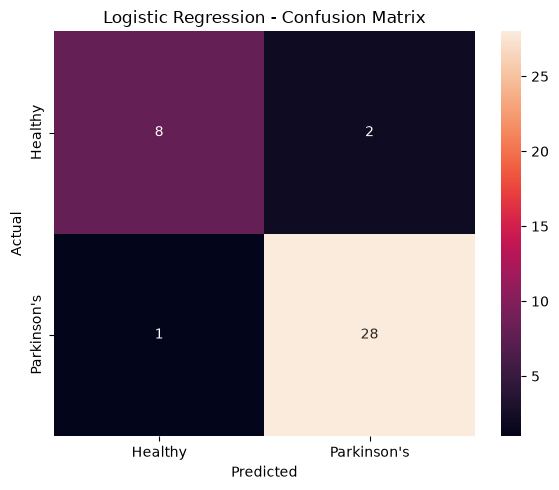

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Confusion Matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=["Healthy", "Parkinson's"],
    yticklabels=["Healthy", "Parkinson's"]
)

plt.title("Logistic Regression - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()

plt.savefig(
    "../outputs/figures/logistic_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [8]:
from sklearn.neighbors import KNeighborsClassifier

knn_model = KNeighborsClassifier(n_neighbors=5)

knn_model.fit(X_train_selected, y_train)

print("KNN trained successfully!")

KNN trained successfully!


In [9]:
# KNN predictions and evaluation

y_pred_knn = knn_model.predict(X_test_selected)
y_prob_knn = knn_model.predict_proba(X_test_selected)[:, 1]

accuracy_knn = accuracy_score(y_test, y_pred_knn)
precision_knn = precision_score(y_test, y_pred_knn)
recall_knn = recall_score(y_test, y_pred_knn)
f1_knn = f1_score(y_test, y_pred_knn)
roc_auc_knn = roc_auc_score(y_test, y_prob_knn)

print("KNN Results")
print("-----------")
print(f"Accuracy : {accuracy_knn:.4f}")
print(f"Precision: {precision_knn:.4f}")
print(f"Recall   : {recall_knn:.4f}")
print(f"F1-Score : {f1_knn:.4f}")
print(f"ROC-AUC  : {roc_auc_knn:.4f}")

KNN Results
-----------
Accuracy : 0.8718
Precision: 0.9615
Recall   : 0.8621
F1-Score : 0.9091
ROC-AUC  : 0.9414


In [10]:
from sklearn.svm import SVC

svm_model = SVC(
    kernel="rbf",
    probability=True,
    random_state=42
)

svm_model.fit(X_train_selected, y_train)

print("SVM trained successfully!")

SVM trained successfully!


/Users/devtrivedi/parkinsons_ml_project/.venv/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


In [11]:
# SVM predictions and evaluation

y_pred_svm = svm_model.predict(X_test_selected)
y_prob_svm = svm_model.predict_proba(X_test_selected)[:, 1]

accuracy_svm = accuracy_score(y_test, y_pred_svm)
precision_svm = precision_score(y_test, y_pred_svm)
recall_svm = recall_score(y_test, y_pred_svm)
f1_svm = f1_score(y_test, y_pred_svm)
roc_auc_svm = roc_auc_score(y_test, y_prob_svm)

print("SVM Results")
print("-----------")
print(f"Accuracy : {accuracy_svm:.4f}")
print(f"Precision: {precision_svm:.4f}")
print(f"Recall   : {recall_svm:.4f}")
print(f"F1-Score : {f1_svm:.4f}")
print(f"ROC-AUC  : {roc_auc_svm:.4f}")

SVM Results
-----------
Accuracy : 0.9231
Precision: 0.9333
Recall   : 0.9655
F1-Score : 0.9492
ROC-AUC  : 0.9345


In [12]:
from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier(
    random_state=42,
    max_depth=5
)

dt_model.fit(X_train_selected, y_train)

print("Decision Tree trained successfully!")

Decision Tree trained successfully!


In [13]:
# Decision Tree predictions and evaluation

y_pred_dt = dt_model.predict(X_test_selected)
y_prob_dt = dt_model.predict_proba(X_test_selected)[:, 1]

accuracy_dt = accuracy_score(y_test, y_pred_dt)
precision_dt = precision_score(y_test, y_pred_dt)
recall_dt = recall_score(y_test, y_pred_dt)
f1_dt = f1_score(y_test, y_pred_dt)
roc_auc_dt = roc_auc_score(y_test, y_prob_dt)

print("Decision Tree Results")
print("--------------------")
print(f"Accuracy : {accuracy_dt:.4f}")
print(f"Precision: {precision_dt:.4f}")
print(f"Recall   : {recall_dt:.4f}")
print(f"F1-Score : {f1_dt:.4f}")
print(f"ROC-AUC  : {roc_auc_dt:.4f}")

Decision Tree Results
--------------------
Accuracy : 0.7692
Precision: 0.8571
Recall   : 0.8276
F1-Score : 0.8421
ROC-AUC  : 0.7414


In [14]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)

rf_model.fit(X_train_selected, y_train)

print("Random Forest trained successfully!")

Random Forest trained successfully!


In [15]:
# Random Forest predictions and evaluation

y_pred_rf = rf_model.predict(X_test_selected)
y_prob_rf = rf_model.predict_proba(X_test_selected)[:, 1]

accuracy_rf = accuracy_score(y_test, y_pred_rf)
precision_rf = precision_score(y_test, y_pred_rf)
recall_rf = recall_score(y_test, y_pred_rf)
f1_rf = f1_score(y_test, y_pred_rf)
roc_auc_rf = roc_auc_score(y_test, y_prob_rf)

print("Random Forest Results")
print("--------------------")
print(f"Accuracy : {accuracy_rf:.4f}")
print(f"Precision: {precision_rf:.4f}")
print(f"Recall   : {recall_rf:.4f}")
print(f"F1-Score : {f1_rf:.4f}")
print(f"ROC-AUC  : {roc_auc_rf:.4f}")

Random Forest Results
--------------------
Accuracy : 0.8974
Precision: 0.9310
Recall   : 0.9310
F1-Score : 0.9310
ROC-AUC  : 0.9534


In [16]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    n_estimators=200,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric="logloss",
    random_state=42
)

xgb_model.fit(X_train_selected, y_train)

print("XGBoost trained successfully!")

XGBoost trained successfully!


In [17]:
# XGBoost predictions and evaluation

y_pred_xgb = xgb_model.predict(X_test_selected)
y_prob_xgb = xgb_model.predict_proba(X_test_selected)[:, 1]

accuracy_xgb = accuracy_score(y_test, y_pred_xgb)
precision_xgb = precision_score(y_test, y_pred_xgb)
recall_xgb = recall_score(y_test, y_pred_xgb)
f1_xgb = f1_score(y_test, y_pred_xgb)
roc_auc_xgb = roc_auc_score(y_test, y_prob_xgb)

print("XGBoost Results")
print("----------------")
print(f"Accuracy : {accuracy_xgb:.4f}")
print(f"Precision: {precision_xgb:.4f}")
print(f"Recall   : {recall_xgb:.4f}")
print(f"F1-Score : {f1_xgb:.4f}")
print(f"ROC-AUC  : {roc_auc_xgb:.4f}")

XGBoost Results
----------------
Accuracy : 0.8462
Precision: 0.8966
Recall   : 0.8966
F1-Score : 0.8966
ROC-AUC  : 0.9276


In [18]:
# Compare all six models

results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "KNN",
        "SVM",
        "Decision Tree",
        "Random Forest",
        "XGBoost"
    ],
    "Accuracy": [
        accuracy,
        accuracy_knn,
        accuracy_svm,
        accuracy_dt,
        accuracy_rf,
        accuracy_xgb
    ],
    "Precision": [
        precision,
        precision_knn,
        precision_svm,
        precision_dt,
        precision_rf,
        precision_xgb
    ],
    "Recall": [
        recall,
        recall_knn,
        recall_svm,
        recall_dt,
        recall_rf,
        recall_xgb
    ],
    "F1-Score": [
        f1,
        f1_knn,
        f1_svm,
        f1_dt,
        f1_rf,
        f1_xgb
    ],
    "ROC-AUC": [
        roc_auc,
        roc_auc_knn,
        roc_auc_svm,
        roc_auc_dt,
        roc_auc_rf,
        roc_auc_xgb
    ]
})

results = results.sort_values(
    by="F1-Score",
    ascending=False
).reset_index(drop=True)

results

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.923077,0.933333,0.965517,0.949153,0.920690
1,SVM,0.923077,0.933333,0.965517,0.949153,0.934483
2,Random Forest,0.897436,0.931034,0.931034,0.931034,0.953448
3,KNN,0.871795,0.961538,0.862069,0.909091,0.941379
4,XGBoost,0.846154,0.896552,0.896552,0.896552,0.927586
5,Decision Tree,0.769231,0.857143,0.827586,0.842105,0.741379


In [19]:
# Identify the best-performing model

best_model = results.iloc[0]

print("Best Model:")
print(best_model["Model"])

print("\nPerformance:")
print(best_model)

Best Model:
Logistic Regression

Performance:
Model        Logistic Regression
Accuracy                0.923077
Precision               0.933333
Recall                  0.965517
F1-Score                0.949153
ROC-AUC                  0.92069
Name: 0, dtype: object


In [20]:
# Select the best model for tuning

best_model_name = results.iloc[0]["Model"]

print("Model selected for tuning:", best_model_name)

Model selected for tuning: Logistic Regression


In [21]:
from sklearn.model_selection import GridSearchCV

if best_model_name == "Logistic Regression":
    model = LogisticRegression(max_iter=1000, random_state=42)
    param_grid = {
        "C": [0.01, 0.1, 1, 10, 100],
        "solver": ["liblinear", "lbfgs"]
    }

elif best_model_name == "KNN":
    model = KNeighborsClassifier()
    param_grid = {
        "n_neighbors": [3, 5, 7, 9, 11],
        "weights": ["uniform", "distance"],
        "metric": ["euclidean", "manhattan"]
    }

elif best_model_name == "SVM":
    model = SVC(probability=True, random_state=42)
    param_grid = {
        "C": [0.1, 1, 10, 100],
        "gamma": ["scale", "auto"],
        "kernel": ["rbf", "linear"]
    }

elif best_model_name == "Decision Tree":
    model = DecisionTreeClassifier(random_state=42)
    param_grid = {
        "max_depth": [3, 5, 7, 10, None],
        "min_samples_split": [2, 5, 10],
        "min_samples_leaf": [1, 2, 4]
    }

elif best_model_name == "Random Forest":
    model = RandomForestClassifier(random_state=42)
    param_grid = {
        "n_estimators": [100, 200, 300],
        "max_depth": [None, 5, 10, 15],
        "min_samples_split": [2, 5, 10]
    }

elif best_model_name == "XGBoost":
    model = XGBClassifier(
        eval_metric="logloss",
        random_state=42
    )
    param_grid = {
        "n_estimators": [100, 200, 300],
        "max_depth": [3, 4, 5],
        "learning_rate": [0.01, 0.05, 0.1]
    }

grid_search = GridSearchCV(
    estimator=model,
    param_grid=param_grid,
    scoring="f1",
    cv=5,
    n_jobs=-1
)

grid_search.fit(X_train_selected, y_train)

print("Best parameters:")
print(grid_search.best_params_)

print("\nBest cross-validation F1-score:")
print(f"{grid_search.best_score_:.4f}")

Best parameters:
{'C': 0.1, 'solver': 'lbfgs'}

Best cross-validation F1-score:
0.8875


In [22]:
# Evaluate the tuned model

best_tuned_model = grid_search.best_estimator_

y_pred_tuned = best_tuned_model.predict(X_test_selected)
y_prob_tuned = best_tuned_model.predict_proba(X_test_selected)[:, 1]

accuracy_tuned = accuracy_score(y_test, y_pred_tuned)
precision_tuned = precision_score(y_test, y_pred_tuned)
recall_tuned = recall_score(y_test, y_pred_tuned)
f1_tuned = f1_score(y_test, y_pred_tuned)
roc_auc_tuned = roc_auc_score(y_test, y_prob_tuned)

print("Tuned Model Results")
print("-------------------")
print(f"Model    : {best_model_name}")
print(f"Accuracy : {accuracy_tuned:.4f}")
print(f"Precision: {precision_tuned:.4f}")
print(f"Recall   : {recall_tuned:.4f}")
print(f"F1-Score : {f1_tuned:.4f}")
print(f"ROC-AUC  : {roc_auc_tuned:.4f}")

Tuned Model Results
-------------------
Model    : Logistic Regression
Accuracy : 0.8718
Precision: 0.8750
Recall   : 0.9655
F1-Score : 0.9180
ROC-AUC  : 0.9034


In [23]:
# Compare original and tuned model

comparison = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score",
        "ROC-AUC"
    ],
    "Original": [
        results.loc[
            results["Model"] == best_model_name, "Accuracy"
        ].iloc[0],
        results.loc[
            results["Model"] == best_model_name, "Precision"
        ].iloc[0],
        results.loc[
            results["Model"] == best_model_name, "Recall"
        ].iloc[0],
        results.loc[
            results["Model"] == best_model_name, "F1-Score"
        ].iloc[0],
        results.loc[
            results["Model"] == best_model_name, "ROC-AUC"
        ].iloc[0]
    ],
    "Tuned": [
        accuracy_tuned,
        precision_tuned,
        recall_tuned,
        f1_tuned,
        roc_auc_tuned
    ]
})

comparison

,Metric,Original,Tuned
0,Accuracy,0.923077,0.871795
1,Precision,0.933333,0.875000
2,Recall,0.965517,0.965517
3,F1-Score,0.949153,0.918033
4,ROC-AUC,0.920690,0.903448


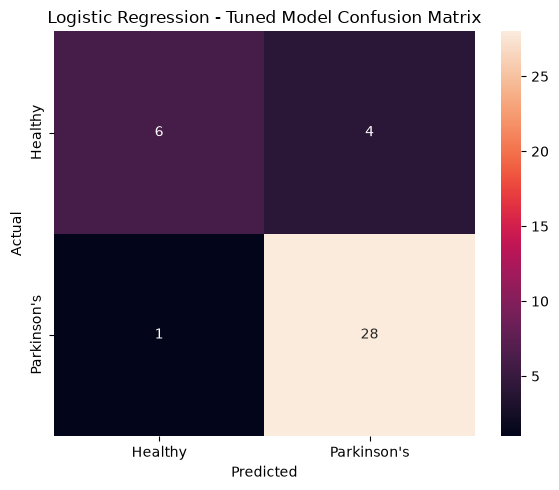

In [24]:
# Confusion Matrix for the Tuned Model

cm_tuned = confusion_matrix(y_test, y_pred_tuned)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_tuned,
    annot=True,
    fmt="d",
    xticklabels=["Healthy", "Parkinson's"],
    yticklabels=["Healthy", "Parkinson's"]
)

plt.title(f"{best_model_name} - Tuned Model Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()

plt.savefig(
    "../outputs/figures/tuned_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [25]:
import shap

# Create SHAP explainer for the tuned model

explainer = shap.Explainer(
    best_tuned_model,
    X_train_selected
)

shap_values = explainer(X_test_selected)

print("SHAP explanation generated successfully!")

Background dataset has 156 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=156 when initializing the masker.


SHAP explanation generated successfully!


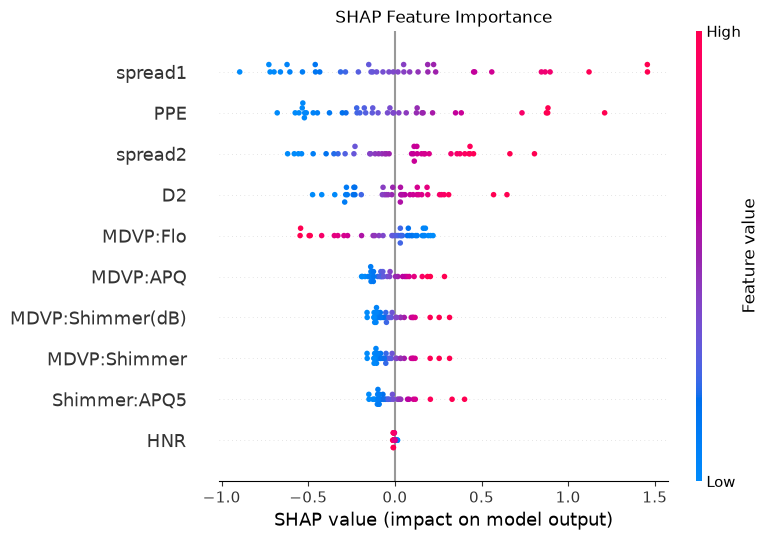

In [26]:
# SHAP feature importance

shap.summary_plot(
    shap_values,
    X_test_selected,
    feature_names=selected_features,
    show=False
)

plt.title("SHAP Feature Importance")
plt.tight_layout()

plt.savefig(
    "../outputs/figures/shap_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Actual class: 0
Predicted class: 1


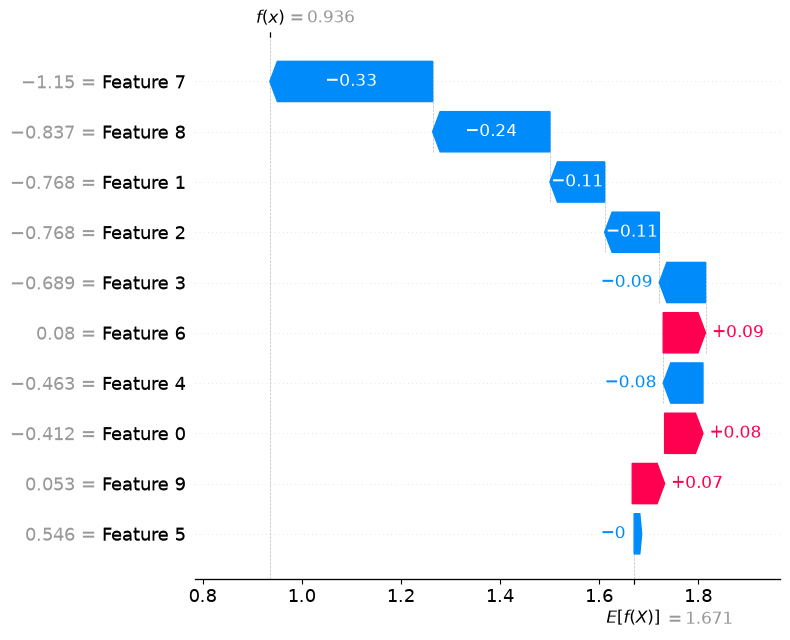

In [27]:
# Explain one individual prediction

sample_index = 0

print("Actual class:", y_test.iloc[sample_index])
print("Predicted class:", y_pred_tuned[sample_index])

shap.plots.waterfall(
    shap_values[sample_index],
    max_display=10,
    show=False
)

plt.tight_layout()

plt.savefig(
    "../outputs/figures/shap_individual_prediction.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [28]:
import joblib

model_artifacts = {
    "scaler": scaler,
    "selector": selector,
    "model": best_tuned_model,
    "selected_features": selected_features.tolist()
}

joblib.dump(
    model_artifacts,
    "../models/parkinsons_pipeline.joblib"
)

print("Final model pipeline saved successfully!")
print("File: models/parkinsons_pipeline.joblib")

Final model pipeline saved successfully!
File: models/parkinsons_pipeline.joblib
